# Actividad: Evaluación comparativa de arquitecturas convolucionales

Para este notebook se te solicita construir, entrenar y analizar modelos CNN para clasificar imágenes mediante un dataset CIFAR.

**Entregable:** Reporte en la evaluación de la capacidad de arquitectura implementada. Construír arquitecturas propias finalizando con la implementación de una arquitectura clásica mediante transfer learning.


## Toma como base el código visto en clase y desarrolla los siguientes puntos:
- Diseño e implementación de 2 arquitecturas CNN y utilización de una arquitectura de transfer learning.

- Buen uso de data augmentation y regularización.

- Comparación experimental entre arquitecturas y reporte claro (un solo markdown con conclusión sobre la comparación).





## Definiciones de modelos

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2

# (seleccióna la arquitectura que desees, puedes buscar otras) VGG16, ResNet50, MobileNetV2


## Carga y preparación de CIFAR-10

In [5]:
from tensorflow.keras.datasets import cifar10

(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# Tomar 5,000 ejemplos y convertir los píxeles de 0–255 a 0–1
X_train = X_train[:5000].astype("float32") / 255.0
y_train = y_train[:5000].ravel()

## Entrenamiento de modelos.

In [6]:
# Recuerda aquí solo generar las arquitecturas, cada capa así como sus neuronas.

from tensorflow.keras.applications import MobileNetV2

modelo_mobilenet = MobileNetV2(
    input_shape=(32, 32, 3),
    weights=None,
    include_top=True,
    classes=10
)

modelo_mobilenet.summary()

Model: "mobilenetv2_1.00_32"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 32, 32, 3)]          0         []                            
                                                                                                  
 Conv1 (Conv2D)              (None, 16, 16, 32)           864       ['input_1[0][0]']             
                                                                                                  
 bn_Conv1 (BatchNormalizati  (None, 16, 16, 32)           128       ['Conv1[0][0]']               
 on)                                                                                              
                                                                                                  
 Conv1_relu (ReLU)           (None, 16, 16, 32)           0         ['bn_Conv1[0

In [7]:
# Aquí agrega la compilación y entrenamiento de las arquitecturas generadas.

modelo_mobilenet.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

historial_mobilenet = modelo_mobilenet.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/3
125/125 [==============================] - 4s 25ms/step - loss: 2.5545 - accuracy: 0.1507 - val_loss: 2.3031 - val_accuracy: 0.0850
Epoch 2/3
125/125 [==============================] - 3s 23ms/step - loss: 2.1327 - accuracy: 0.2188 - val_loss: 2.3062 - val_accuracy: 0.0850
Epoch 3/3
125/125 [==============================] - 3s 24ms/step - loss: 1.9552 - accuracy: 0.2760 - val_loss: 2.3060 - val_accuracy: 0.0950


## Estadística y gráficos

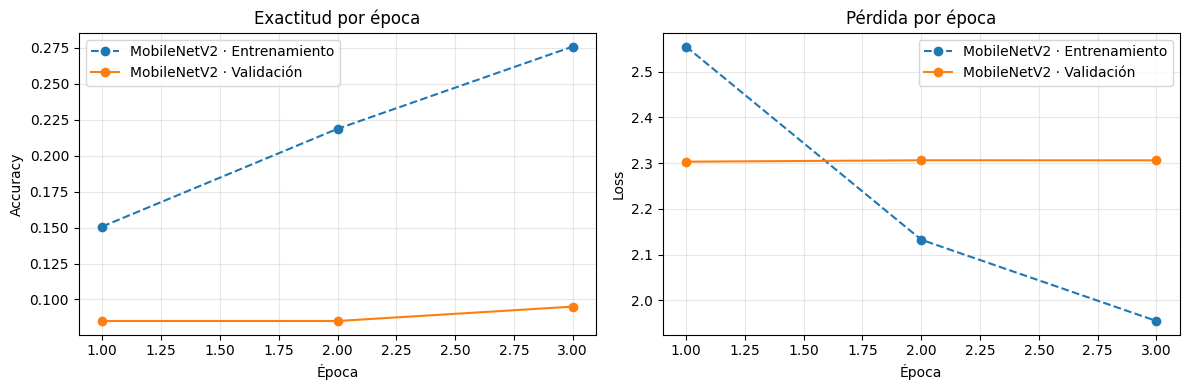

In [10]:
# Puedes tomar como base el código visto en clase para generar las graficos de comparación de las arquitecturas o puedes proptear tu propia forma de visualización.

%matplotlib inline
import matplotlib.pyplot as plt

historiales = {
    "MobileNetV2": historial_mobilenet,
    # Agrega aquí el segundo modelo cuando lo entrenes.
    # "CNN sencilla": historial_cnn,
}

fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(12, 4))

for nombre, historial in historiales.items():
    datos = historial.history
    epocas = range(1, len(datos["loss"]) + 1)

    ax_acc.plot(epocas, datos["accuracy"], "o--", label=f"{nombre} · Entrenamiento")
    ax_acc.plot(epocas, datos["val_accuracy"], "o-", label=f"{nombre} · Validación")

    ax_loss.plot(epocas, datos["loss"], "o--", label=f"{nombre} · Entrenamiento")
    ax_loss.plot(epocas, datos["val_loss"], "o-", label=f"{nombre} · Validación")

ax_acc.set(title="Exactitud por época", xlabel="Época", ylabel="Accuracy")
ax_loss.set(title="Pérdida por época", xlabel="Época", ylabel="Loss")

for ax in (ax_acc, ax_loss):
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Conclusiones.

Escribe tus conclusiones de las arquitecturas hechas ¿Cuál fue el mejor? ¿Por qué? ¿Qué mejoraría? ¿Cómo lo mejoraría?

En esta práctica entrené MobileNetV2 desde cero durante tres épocas con un subconjunto de CIFAR-10. Elegí esta arquitectura porque requiere menos recursos que VGG16 y ResNet50, lo que facilitó probarla en mi computadora. Sin embargo, como solo entrené MobileNetV2, no puedo concluir que haya sido la mejor. Las gráficas muestran cómo se comportó el mismo modelo durante el entrenamiento y la validación, no cómo se compara con otras arquitecturas.

Para mejorar el modelo, usaría más imágenes de entrenamiento y probaría un aumento de datos con transformaciones sencillas, como volteos horizontales. También permitiría más épocas y usaría `EarlyStopping` para conservar los pesos de la época con menor pérdida de validación. Para decidir qué arquitectura conviene más, entrenaría una CNN sencilla como referencia con la misma división de datos. Después compararía la exactitud de ambos modelos en el mismo conjunto de prueba y el tiempo que tardan en hacer predicciones.